# Ro-vibrational Spectra of Hydrogen

The ro-vibrational spectrum of hydrogen, a linear molecule, is computed by the phase-space sampling (see also section III D of the paper).

| Redundant space | Potential | Integrator | Physical space |
|---|---|---|---|
| Cartesian (6 DOFs) with 3 constraints (3 translations) | `H2SplinePotential` | `ShakeRattle` | bond length $r$, polar $\theta$ and azimuthal angle $\phi$ |

- **Ro-vibration**: Only the center of mass is fixed by constraints, so that the molecule vibrates while rotating. The analytical Hessian of `H2SplinePotential` is used at every step.

- **Initial states**: Coherent states centered at the equilibrium structure, in the vibrational ground state ($v = 0$) with the rotational kinetic energies of 500, 2000 and 5000 $\textrm{cm}^{-1}$.
  
- **Sampling**: As in the pure rotation, the initial positions are fixed at the equilibrium structure, and only the momenta are sampled, including the vibrational momenta (see below).

- **Reference**: The peaks are compared with the Dunham expansion for $v = 0$ using the experimental parameters.


In [1]:
# import necessary libraries

import sys
import time
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))

import numpy as np

from pyscivr.units import FemtoSec, CmInv, HBar
from pyscivr.potentials import H2SplinePotential
from pyscivr.coordinates import InternalCoordinates
from pyscivr.integrators import ShakeRattle
from pyscivr.variations import make_vari_propagator, propagate_variation, make_jacobi_func, to_internal
from pyscivr.basis import get_overlap
from pyscivr.scivr import get_lagrangian, get_action, get_prefactor, get_ta_spectrum_fft

## System and coordinates

The system and the coordinates are the same as in the Hessian and Variation tutorial:
`COORD_CONST` defines the constraints (center of mass), and `COORD_ALL` defines the full set of coordinates,
where the bond length and the polar and azimuthal angles are active.

## Sampling of the initial conditions

`sample_momenta` samples `K_rot`, `tilt`, the vibrational kinetic energy `K_vib` and the sign of the vibrational
momentum uniformly.

The vibrational momenta are sampled even for the vibrational ground state.
In the ground state, the molecule still vibrates with the zero-point motion, and the rotational levels are determined by the rotational constant averaged over this motion, $B_0$, which is smaller than that at the equilibrium structure, $B_e$. 
Sampling the vibrational momenta takes this ro-vibrational coupling into account.

## Calculation of the spectra

`run` computes the spectra for all the initial states by the following steps for each trajectory:

1. Propagate the trajectory by `ShakeRattle`.
2. Propagate the variation and compute the monodromy matrix in the physical space.
   The Hessian is zero for `H2SplinePotential`.
3. Exclude the steps where the symplectic condition is not satisfied.
4. Compute the action, the prefactor and the overlap with each initial state, and the spectrum
   by the FFT.

The spectra are averaged over the trajectories and saved for each initial state.
Note that each trajectory is used for all the initial states, so that the cost of the dynamics
and the monodromy matrix is shared.

In [ ]:
# Constants
MASS = np.array([1.008, 1.008]) # mass of hydrogen atoms [amu (atomic mass unit)]
OMEGA_E = 4401.226  # vibrational frequency of bond stretching [cm^-1]
R_E = 0.74160392 # equilibrium bond length [Angs]
POSI_REF = np.array([[-R_E / 2, 0.0, 0.0], [R_E / 2, 0.0, 0.0]])
CALC = H2SplinePotential()
ENER_REF = CALC.energy(POSI_REF)

# Coordinate for constraints
COORD_CONST = InternalCoordinates(POSI_REF, MASS)
COORD_CONST.add_translation()
COORD_CONST.build()

# Coordinate for all DOFs
COORD_ALL = InternalCoordinates(POSI_REF, MASS)
COORD_ALL.add_translation()
COORD_ALL.add_polar(0, 1)
COORD_ALL.add_azimuthal(0, 1)
COORD_ALL.add_bond(0, 1)
COORD_ALL.build()

ACTIVE_IDX = np.array([COORD_ALL.find_coordinate(kind, (0, 1))[0] for kind in ("bond", "polar", "azimuthal")])
TOPOLOGIES = [COORD_ALL.topology[i] for i in ACTIVE_IDX]

JACOBI_FUNC, JACOBI_REV_FUNC, INTERNAL_FUNC, MONODROMY_FUNC = make_jacobi_func(COORD_ALL, ACTIVE_IDX)


def initial_momenta(K_rot, K_vib, tilt, sign=1):

    p_rot = np.sqrt(K_rot * CmInv * MASS[0])
    p_vib = np.sqrt(K_vib * CmInv * MASS[0]) * sign
    p_rot_y = p_rot * np.cos(tilt)
    p_rot_z = p_rot * np.sin(tilt)
    return np.array([[-p_vib, -p_rot_y, -p_rot_z], [p_vib, p_rot_y, p_rot_z]])


def sample_momenta(n_sample, K_rot_range, K_vib_range, seed=10202):

    rng = np.random.default_rng(seed)
    K_rot = rng.uniform(*K_rot_range, size=n_sample)
    K_vib = rng.uniform(*K_vib_range, size=n_sample)
    sign = rng.choice([-1, 1], size=n_sample)
    tilt = rng.uniform(0.0, 2.0 * np.pi, size=n_sample)
    return [initial_momenta(K_rot[i], K_vib[i], tilt[i], sign[i]) for i in range(n_sample)], K_rot, K_vib


def run(posi_sample_list, mome_sample_list, K_rot_list, K_vib_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft, symp_err_tol=1e-4):

    # Judge function to check if the point is singular or not
    judge_func= lambda symp_err : np.isfinite(symp_err) & (symp_err < symp_err_tol)

    # Reference positions and momenta in the internal coordinates
    posi_ref_int, mome_ref_int = zip(*[INTERNAL_FUNC(p, q) for p, q in zip(posi_ref_list, mome_ref_list)])

    n_sample = len(posi_sample_list)
    n_ref = len(posi_ref_list)
    spectra = [0.0] * n_ref
    vari_propagator = make_vari_propagator(COORD_CONST, dt)

    t_start = time.perf_counter()
    for i in range(n_sample):
        # Get trajectory
        dyn = ShakeRattle(CALC, posi_sample_list[i], mome_sample_list[i], MASS, dt, COORD_CONST)
        traj = dyn.run(n_step)
        traj_posi, traj_mome = traj["posi"], traj["mome"]

        # get variation
        hess = CALC.hessian(traj_posi)
        J_rev_init = JACOBI_REV_FUNC(traj_posi[0], traj_mome[0])

        vari = propagate_variation(vari_propagator, traj_posi, traj_mome, traj["lam"], traj["mu"], hess, vari_init=J_rev_init)
        posi_int, mome_int, mono_int, symplectic_error = to_internal(MONODROMY_FUNC, traj_posi, traj_mome, vari)

        # points with large symplectic error are treated as singularities
        valid = judge_func(symplectic_error)

        ener_grid = 2.0 * np.pi * HBar * np.arange(n_fft) / (dt * n_fft)
        lag = get_lagrangian(traj["total_energy"], traj["potential_energy"], ener_ref=ENER_REF)
        action = get_action(lag, dt)

        for j in range(n_ref):
            posi_center, mome_center = posi_ref_int[j], mome_ref_int[j]
            gamma = gamma_ref_list[j]
            prefactor = get_prefactor(mono_int, gamma, valid=valid)
            overlap = get_overlap(TOPOLOGIES, posi_center, mome_center, posi_int, mome_int, gamma)
            _, spec = get_ta_spectrum_fft(prefactor, overlap, action, dt, n_fft, valid=valid)
            spectra[j] += spec

        if i % 10 == 0:
            print(f"{i+1:6d} / {n_sample}, K_rot = {K_rot_list[i]:.1f}, K_vib = {K_vib_list[i]:.1f}, "
                f"max symp error = {np.max(np.abs(symplectic_error)):.3e}, ({time.perf_counter() - t_start:.1f} sec)", flush=True)

    for j in range(n_ref):
        spectra[j] /= n_sample

    for j in range(n_ref):
        np.savez(fpath_list[j], ener_grid=ener_grid, spectrum=spectra[j])

Build complete: 3 coordinates
Build complete: 6 coordinates


## Execute the calculation

The total propagation time is 500 fs.

In [3]:
if __name__ == "__main__":
    # set parameters
    n_sample = 2000
    dt = 0.1 * FemtoSec
    n_step = 5000
    n_fft = 2**19

    # set reference state
    K_rot_ref_list = [500.0, 2000.0, 5000.0]

    # no vibrational kinetic energy for the reference state to target the vibrational ground state (v=0)
    mome_ref_list = [initial_momenta(k_rot, 0.0, np.pi / 4) for k_rot in K_rot_ref_list]
    posi_ref_list = [POSI_REF] * len(K_rot_ref_list)

    omega_e = OMEGA_E * CmInv / HBar  # convert to internal unit
    gamma_ref = [MASS[0] * omega_e / (2.0 * HBar), # harmoninc width (m_H * omega / 2 hbar)
                 1.0 / (2 * 0.2 ** 2),  # sqrt(1 / 2 gamma) = 0.2 rad
                 1.0 / (2 * 0.2 ** 2)]
    gamma_ref_list = [gamma_ref] * len(K_rot_ref_list)
    fpath_list = [f"hydrogen_rovib_{k_rot:.0f}_v0_n_{n_sample}_spectra.npz" for k_rot in K_rot_ref_list]

    posi_ref_list = np.asarray(posi_ref_list)
    mome_ref_list = np.asarray(mome_ref_list)
    gamma_ref_list = np.asarray(gamma_ref_list)

    K_rot_range = (10.0, 10000.0)
    K_vib_range = (0.0, OMEGA_E)
    mome_sample_list, K_rot_list, K_vib_list = sample_momenta(n_sample, K_rot_range, K_vib_range)
    posi_sample_list = np.asarray([POSI_REF] * n_sample)

    run(posi_sample_list, mome_sample_list, K_rot_list, K_vib_list,
        posi_ref_list, mome_ref_list, gamma_ref_list, fpath_list,
        dt, n_step, n_fft)

     1 / 2000, K_rot = 2788.2, K_vib = 2483.7, max symp error = 5.123e-10, (1.1 sec)
    11 / 2000, K_rot = 4946.9, K_vib = 1226.6, max symp error = 3.353e-10, (5.5 sec)
    21 / 2000, K_rot = 9808.5, K_vib = 3522.1, max symp error = 5.238e-10, (10.1 sec)
    31 / 2000, K_rot = 8930.5, K_vib = 2197.7, max symp error = 3.750e-10, (14.5 sec)
    41 / 2000, K_rot = 1592.5, K_vib = 1338.6, max symp error = 1.258e-09, (19.1 sec)
    51 / 2000, K_rot = 7396.6, K_vib = 900.2, max symp error = 2.789e-10, (23.6 sec)
    61 / 2000, K_rot = 2192.0, K_vib = 3063.7, max symp error = 8.678e-10, (28.2 sec)
    71 / 2000, K_rot = 6597.3, K_vib = 3239.4, max symp error = 2.735e-10, (32.8 sec)
    81 / 2000, K_rot = 2769.8, K_vib = 3814.3, max symp error = 8.734e-10, (37.5 sec)
    91 / 2000, K_rot = 2161.3, K_vib = 2645.7, max symp error = 1.251e-09, (42.0 sec)
   101 / 2000, K_rot = 3024.0, K_vib = 1407.6, max symp error = 1.468e-09, (46.6 sec)
   111 / 2000, K_rot = 4798.8, K_vib = 2901.8, max symp e

## Plot results

The reference levels are the experimental ro-vibrational levels of H2 in the vibrational ground state,
given by the Dunham expansion

$$
E_J = E_{\text{ZPE}} + B J(J+1) - D [J(J+1)]^2 + H [J(J+1)]^3 + L [J(J+1)]^4
$$

with the coefficients from D. E. Jennings and J. W. Brault, J. Mol. Spectrosc. **102**, 265-272 (1983).

The zero-point energy is set to $E_{\text{ZPE}}$ = 2183 $\textrm{cm}^{-1}$ here.

Analytical energies (cm^-1): [2183.  2301.5 2537.4 2888.5 3351.8 3923.2 4597.9 5370.5 6234.9 7184.9
 8213.7 9314.4]
Peaks (cm^-1) for K = 500: [2289.1 2537.9 2883.4 3341.4 3915.3 4594.2 5362.1]
Peaks (cm^-1) for K = 2000: [2541.7 2882.1 3340.2 3913.4 4592.3 5362.1 6226.1 7174.7 8204.1]
Peaks (cm^-1) for K = 5000: [3338.3 3912.1 4591.  5361.5 6225.4 7174.1 8203.5 9308.6]


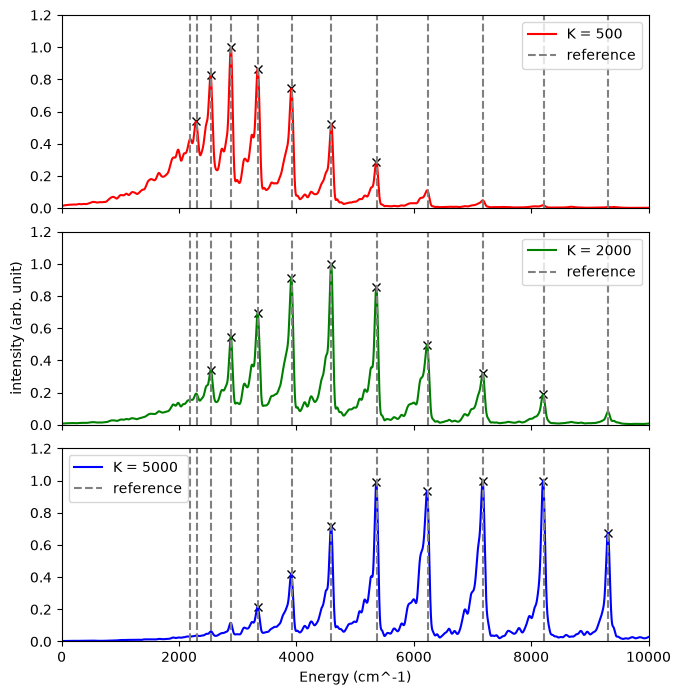

In [4]:
def f(x, B, D, H, L):
    return B*x*(x+1)-D*x*x*(x+1)*(x+1)+H*(x**3)*((x+1)**3)+L*(x**4)*((x+1)**4)

if __name__ == "__main__":
    import matplotlib.pyplot as plt
    from scipy.signal import find_peaks

    # moment of inertia of H2
    I = MASS[0] * R_E**2 / 2.0

    # Dunham expansion coefficients for H2 vibrational ground state
    # D. E. Jennings and J. W. Brault, "The ground state of molecular hydrogen", Journal of Molecular Spectroscopy 102, 265–272 (1983).
    B = 59.334547
    D = 0.0456821
    H = 4.8542e-5
    L = -5.411e-8
    ZPE = 2183.0  # zero-point energy [cm^-1]

    analytical_energies = np.array([f(n, B, D, H, L) + ZPE for n in range(20)])
    analytical_energies = analytical_energies[analytical_energies <= 10000]

    print(f"Analytical energies (cm^-1): {np.round(analytical_energies, 1)}")

    fig, ax = plt.subplots(3, 1, figsize=(7, 7), sharex=True)
    colors = ["red", "green", "blue"]    

    for i, fpath in enumerate(fpath_list):
        data = np.load(fpath)
        ener_grid = data["ener_grid"] / CmInv
        spectrum = data["spectrum"]
        spectrum /= np.max(spectrum)
        peaks, _ = find_peaks(spectrum, height=0.1, prominence=0.1)
        mask = (ener_grid[peaks] <= 10000)
        peaks = peaks[mask]

        print(f"Peaks (cm^-1) for K = {K_rot_ref_list[i]:.0f}: {np.round(ener_grid[peaks], 1)}")
        ax[i].plot(ener_grid[peaks], spectrum[peaks], "x", color="black")

        ax[i].plot(ener_grid, spectrum, label=f"K = {K_rot_ref_list[i]:.0f}", color=colors[i])
        ax[i].set_xlim(0, 10000)
        ax[i].set_ylim(0, 1.2)
        ax[i].vlines(analytical_energies, 0.0, 1.2, color="gray", linestyle="--", label="reference")
        ax[i].legend()

    ax[-1].set_xlabel("Energy (cm^-1)")
    ax[1].set_ylabel("intensity (arb. unit)")
    ax[-1].set_xlim(0, 10000)
    plt.tight_layout()    
    plt.show()

Since the peak corresponding to the vibrational zero-point energy is not clearly resolved, we evaluate the successive intervals $\Delta_J \equiv E_J - E_{J-1}$, which are independent of the choice of the zero-point energy, as in the paper.
The computed intervals from the spectrum for $K$ = 2000 $\textrm{cm}^{-1}$ are compared with the reference values $\Delta_J^{(\text{ref})}$ from the Dunham expansion and the rigid-rotor intervals
$\Delta_J^{(\text{rigid})} = 2 B_e J$ (all in $\textrm{cm}^{-1}$).

| $J$ | $\Delta_J$ | $\Delta_J^{(\text{ref})}$ | $\Delta_J - \Delta_J^{(\text{ref})}$ | $\Delta_J^{(\text{rigid})}$ | $\Delta_J - \Delta_J^{(\text{rigid})}$ |
|---|---|---|---|---|---|
| 3 | 340.4 | 351.1 | −10.7 | 364.9 | −24.5 |
| 4 | 458.1 | 463.3 | −5.2 | 486.6 | −28.5 |
| 5 | 573.2 | 571.4 | +1.8 | 608.2 | −35.0 |
| 6 | 678.9 | 674.7 | +4.2 | 729.8 | −50.9 |
| 7 | 769.8 | 772.6 | −2.8 | 851.5 | −81.7 |
| 8 | 864.0 | 864.5 | −0.5 | 973.1 | −109.1 |
| 9 | 948.6 | 950.0 | −1.4 | 1094.8 | −146.2 |
| 10 | 1029.4 | 1028.8 | +0.6 | 1216.4 | −187.0 |

- The computed intervals reproduce the reference values with an RMSE of about 5 $\textrm{cm}^{-1}$, without systematic dependence on $J$.

- In contrast, the computed intervals deviate from the rigid-rotor values increasingly with $J$, reaching $-187$ $\textrm{cm}^{-1}$ at $J = 10$. The computed spectrum thus follows the Dunham expansion rather than the rigid rotor, showing that the ro-vibrational coupling is properly accounted for.